<h2>Introdução</h2>

Neste estudo, foi utilizado um conjunto de dados histórico da Fórmula 1 (F1 DNF Dataset), que reúne informações detalhadas sobre corridas, pilotos, equipes, circuitos e resultados ao longo de diversas temporadas do campeonato mundial.
O dataset contém variáveis como posição de chegada (positionOrder), pontuação (points), ano da corrida (year), identificação do piloto (driverRef) e um indicador que mostra se o piloto concluiu ou não a corrida (target_finish). Essas informações possibilitaram a realização de análises voltadas à avaliação de desempenho, regularidade e comportamento dos competidores em diferentes contextos históricos da categoria.

O principal objetivo deste trabalho é identificar padrões e tendências de desempenho dos pilotos, considerando aspectos como o número de corridas concluídas, a posição média de chegada e a distribuição das nacionalidades ao longo dos anos. Além disso, busca-se compreender como a evolução técnica da Fórmula 1 impactou a confiabilidade e consistência dos resultados.

As análises foram desenvolvidas em notebooks Jupyter, um ambiente computacional que permite a integração de código Python, visualizações gráficas e textos explicativos (Markdown). Foram utilizadas as bibliotecas Pandas, Matplotlib e NumPy, que possibilitaram o tratamento, a organização e a representação visual dos dados de forma clara, interativa e reprodutível.

In [14]:
import pandas as pd
import matplotlib.pyplot as plt 

In [15]:
df = pd.read_csv("f1_dnf.csv")

df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 31 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   resultId         10000 non-null  int64  
 1   raceId           10000 non-null  int64  
 2   year             10000 non-null  int64  
 3   round            10000 non-null  int64  
 4   grid             10000 non-null  int64  
 5   positionOrder    10000 non-null  int64  
 6   points           9029 non-null   float64
 7   laps             9022 non-null   float64
 8   milliseconds     8982 non-null   object 
 9   fastestLap       10000 non-null  object 
 10  rank             10000 non-null  object 
 11  fastestLapTime   10000 non-null  object 
 12  fastestLapSpeed  9047 non-null   object 
 13  driverRef        10000 non-null  object 
 14  surname          10000 non-null  object 
 15  forename         10000 non-null  object 
 16  dob              10000 non-null  object 
 17  nationality_x

Acima foi feito a extração do dataframe e abaixo foram feitos os ajustes de remover colunas com valores ausentes

In [16]:
df.dropna(axis=1,how='any')
df.replace('\\N', pd.NA, inplace=True)

# Remover as colunas com valores ausentes
df.dropna(axis=1, inplace=True)



df.head()

,resultId,raceId,year,round,grid,positionOrder,driverRef,surname,forename,dob,...,circuitRef,circuitId,name_y,location,country,lat,lng,alt,date,target_finish
0,2460,136,2002,13,11,4,raikkonen,Räikkönen,Kimi,1979-10-17,...,hungaroring,11,McLaren,Budapest,Hungary,47.5789,19.24860,264,2002-08-18,1
1,11565,483,1981,1,23,21,watson,Watson,John,1946-05-04,...,long_beach,43,McLaren,California,USA,33.7651,-118.18900,12,1981-03-15,0
2,18661,772,1958,8,0,26,ruttman,Ruttman,Troy,1930-03-11,...,nurburgring,20,Maserati,Nürburg,Germany,50.3356,6.94750,578,1958-08-03,0
3,25121,1058,2021,8,19,16,mick_schumacher,Schumacher,Mick,1999-03-22,...,red_bull_ring,70,Haas F1 Team,Spielberg,Austria,47.2197,14.76470,678,2021-06-27,0
4,8863,383,1988,12,0,30,modena,Modena,Stefano,1963-05-12,...,monza,14,Euro Brun,Monza,Italy,45.6156,9.28111,162,1988-09-11,0


O gráfico abaixo gerado representa um gráfico de pizza que mostra os anos e suas respectivas porcentagens que o piloto Lewis Hamilton levou positionOrder == 1

In [17]:
df_primeiro_hamilton = df[(df['driverRef'] == 'hamilton') & (df['positionOrder'] == 1)].copy()

quantidade = df_primeiro_hamilton.groupby('year').size()

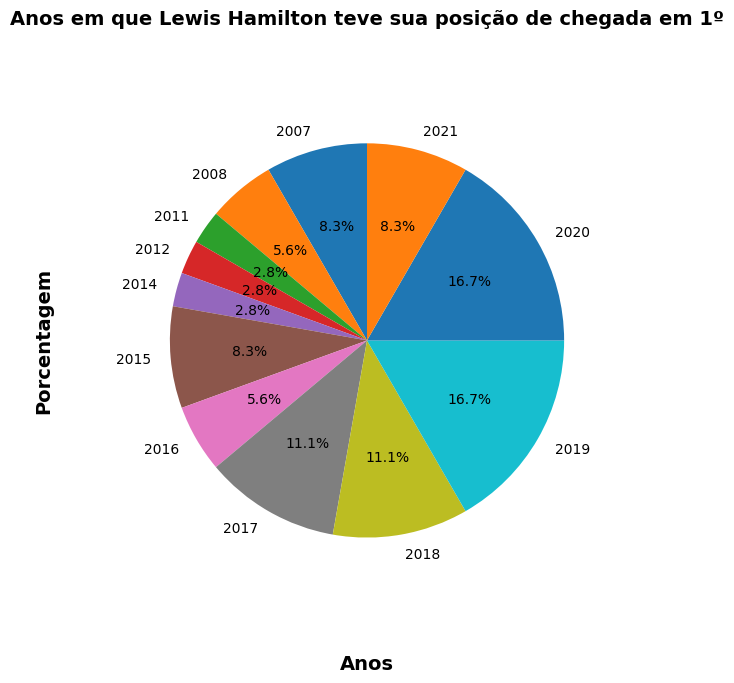

In [19]:
plt.figure(figsize=(10,8))
plt.pie(quantidade, labels=quantidade.index, startangle=90,  radius=0.8, autopct='%1.1f%%')
plt.title("Anos em que Lewis Hamilton teve sua posição de chegada em 1º",fontsize=14, fontweight='bold')
plt.xlabel("Anos",fontsize=14, fontweight='bold')
plt.ylabel("Porcentagem",fontsize=14, fontweight='bold')

plt.show()
